--- Customer Metrics by Loan Acceptance (0 = No, 1 = Yes) ---
  personal_loan      income           cc_avg           mortgage       
                       mean median      mean median        mean median
0             0   66.237389   59.0  1.729009    1.4   51.789381    0.0
1             1  144.745833  142.5  3.905354    3.8  100.845833    0.0


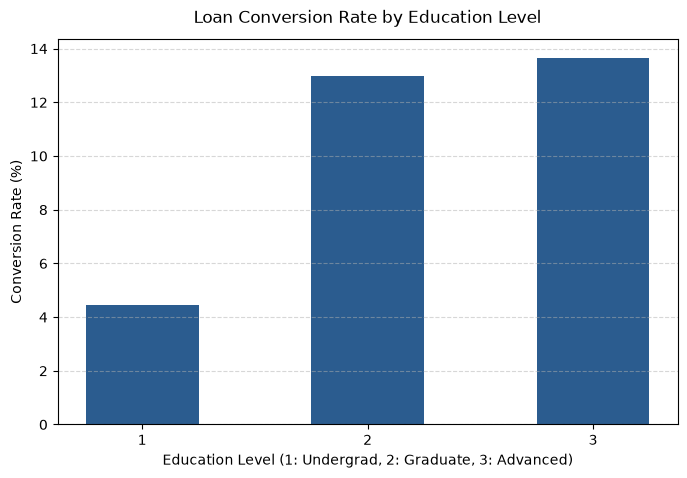

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


df = pd.read_csv(r"C:/Users/user/Downloads/Bank_loan/Bank_Personal_Loan_Modelling.csv")

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "")
    .str.replace(")", "")
    .str.replace(".", "_")
)
df.rename(columns={"ccavg": "cc_avg", "zip_code": "zip_code"}, inplace=True)

summary = (
    df.groupby("personal_loan")[["income", "cc_avg", "mortgage"]]
    .agg(["mean", "median"])
    .reset_index()
)
print("--- Customer Metrics by Loan Acceptance (0 = No, 1 = Yes) ---")
print(summary)

edu_group = df.groupby("education")["personal_loan"].mean().reset_index()
edu_group["conversion_rate_pct"] = edu_group["personal_loan"] * 100

plt.figure(figsize=(8, 5))
plt.bar(
    edu_group["education"].astype(str),
    edu_group["conversion_rate_pct"],
    color="#2b5c8f",
    width=0.5,
)
plt.title("Loan Conversion Rate by Education Level", fontsize=12, pad=12)
plt.xlabel(
    "Education Level (1: Undergrad, 2: Graduate, 3: Advanced)", fontsize=10
)
plt.ylabel("Conversion Rate (%)", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()